<a href="https://colab.research.google.com/github/vivianagonzalez203/Bootcamp-Data-Science/blob/main/03_Datos%20%26%20Visualizaci%C3%B3n/Clase_11_Visualizacion_de_DatosParte_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Clase 11. Visualización de datos parte 2**


## Objetivo

Pasar de gráficos básicos a visualizaciones más cuidadas y útiles para el análisis: combinar paneles, comparar grupos, destacar patrones y construir una figura que pueda presentarse en un contexto profesional.

Al finalizar podrás:
- Organizar 2, 3 o 4 gráficos en una misma figura usando `plt.subplots()`.
- Aplicar jerarquía visual, paletas coherentes, títulos informativos y etiquetas legibles.
- Comparar distribuciones entre categorías y observar relaciones entre variables.
- Interpretar un mapa de calor de correlación sin exagerar lo que los datos dicen.
- Convertir una exploración en una visualización con un mensaje claro.


**Dataset:** reutilizaremos `iris`, visto en la clase 10. No empezaremos desde cero con los tipos de gráficos: nos enfocaremos en combinarlos y mejorar su presentación.

**Idea clave:** un gráfico bonito no es solo decoración. La estética debe mejorar la lectura, la comparación y la comprensión del hallazgo.

## 1. Preparación y repaso

En esta sesión no vamos a dedicar tiempo a explicar de nuevo qué es cada gráfico. Vamos a practicar cómo organizarlos y darles una apariencia consistente.

Si ya tienes `iris` en memoria, el cuaderno lo reutiliza. Si lo abriste desde cero, lo carga con Seaborn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    iris
except NameError:
    iris = sns.load_dataset("iris")

# Estilo general para mantener una apariencia consistente.
sns.set_theme( # Define el estilo general de Seaborn.
    style="whitegrid", # Usa fondo claro con cuadrícula.
    context="notebook", # Ajusta los tamaños para una visualización en cuaderno.
    palette="deep", # Selecciona una paleta de colores.
    font_scale=1.0
)
plt.rcParams.update({ # Permite configurar parámetros generales de Matplotlib.
    "figure.dpi": 110, # Define la resolución de las figuras. Un valor mayor puede producir imágenes más detalladas, aunque también puede aumentar su tamaño
    "axes.titleweight": "bold", # Hace que los títulos aparezcan en negrita.
    "axes.titlepad": 12, #Define el espacio entre el título y el área del gráfico, en puntos.
    "axes.labelcolor": "#344054", # Define el color de las etiquetas de los ejes.
    "axes.titlecolor": "#1D2939", # Define el color de los títulos.
    "grid.alpha": 0.22, # Hace que la cuadrícula sea tenue, con una transparencia de 0.22.
    "axes.spines.top": False, # Oculta el borde superior de los ejes.
    "axes.spines.right": False # Oculta el borde derecho de los ejes.
})

display(iris.head())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Composición avanzada: varios gráficos en una figura

`plt.subplots()` permite organizar una figura como un pequeño panel de análisis. Además de elegir filas y columnas, podemos controlar tamaño, espacios, títulos y ejes.

Para que la figura tenga un acabado más profesional:
- Usa una paleta coherente en toda la figura.
- Evita bordes y cuadrículas innecesarias.
- Escribe títulos que comuniquen el propósito del panel.
- Cuida el tamaño de la figura y los espacios entre gráficos.
- No llenes cada panel de elementos que compitan por la atención.

Primero definimos un estilo común. Esto se aplica a las visualizaciones que creemos después.

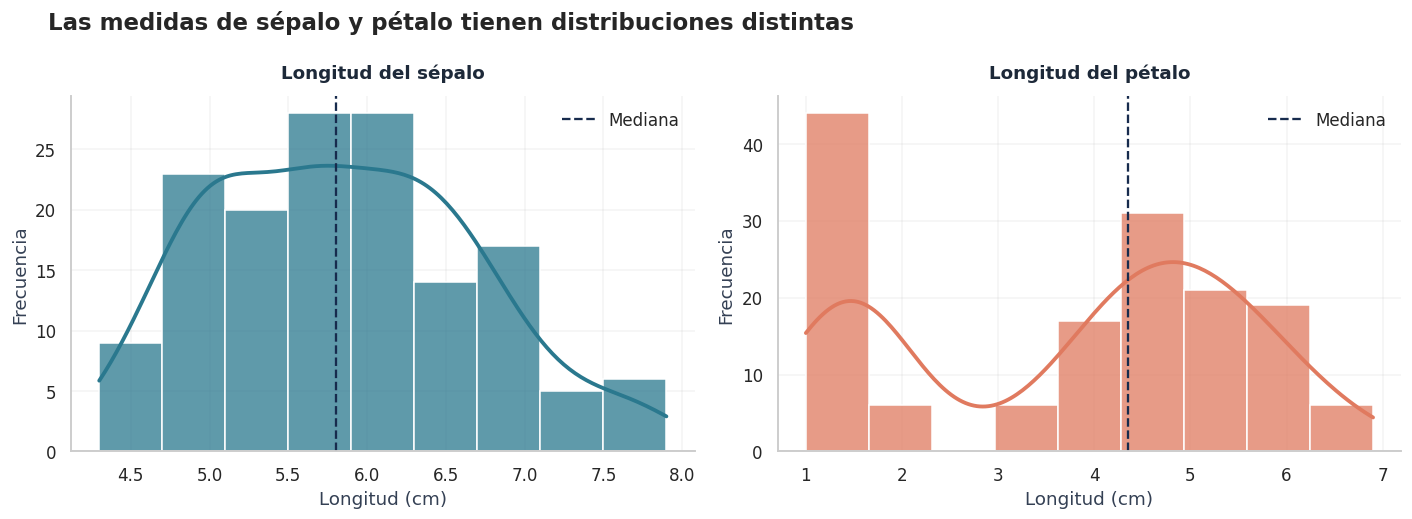

In [4]:
paleta = ["#2A788E", "#E07A5F"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False) # plt.subplots(1, 2): Crea una fila y dos columnas
fig.suptitle("Las medidas de sépalo y pétalo tienen distribuciones distintas",
             fontsize=15, fontweight="bold", x=0.04, ha="left")

sns.histplot(data=iris, x="sepal_length", kde=True, color=paleta[0],  # Agrega línea de tendencia
             alpha=0.75, line_kws={"linewidth": 2.5}, ax=axes[0])
axes[0].axvline(iris["sepal_length"].median(), color="#172B4D", # axes: contiene los espacios individuales donde dibujaremos los gráficos.
                linestyle="--", linewidth=1.5, label="Mediana")
axes[0].set_title("Longitud del sépalo") # ax=axes[0]: indica que este gráfico va en el primer espacio.
axes[0].set_xlabel("Longitud (cm)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(frameon=False)

sns.histplot(data=iris, x="petal_length", kde=True, color=paleta[1],
             alpha=0.75, line_kws={"linewidth": 2.5}, ax=axes[1])
axes[1].axvline(iris["petal_length"].median(), color="#172B4D", # ax=axes[1]: indica que el segundo gráfico va en el segundo espacio.
                linestyle="--", linewidth=1.5, label="Mediana")
axes[1].set_title("Longitud del pétalo") # set_title(): pone el título de cada gráfico.
axes[1].set_xlabel("Longitud (cm)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend(frameon=False)

sns.despine() # Elimina borde superior derecho
plt.tight_layout() # 	plt.tight_layout(): organiza los espacios para que los títulos y las etiquetas no queden montados.
plt.show() # plt.show(): muestra el resultado.

**Cómo leerlo:** cada gráfico muestra cómo se distribuyen los valores de una variable. No tienen que tener la misma forma ni el mismo rango; por eso hay que mirar los títulos y las escalas.

### 2.2 Tres gráficos en una fila

Cuando queremos revisar tres variables, usamos una fila con tres columnas: `plt.subplots(1, 3)`.

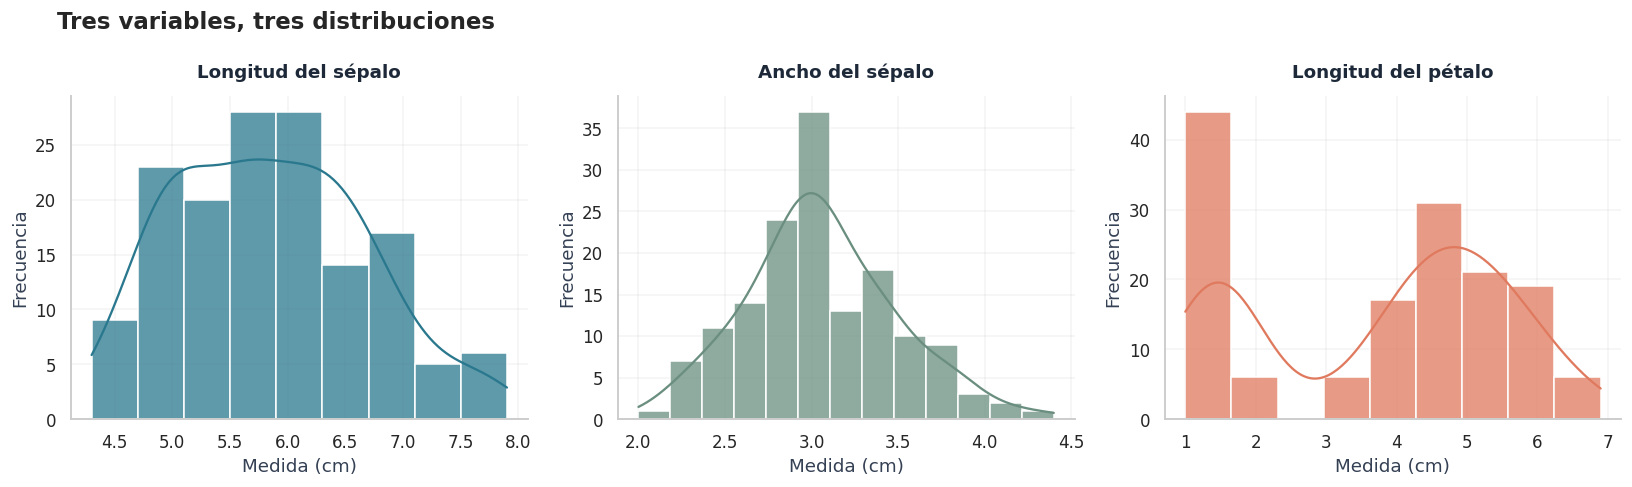

In [5]:
variables = [
    ("sepal_length", "Longitud del sépalo", "#2A788E"),
    ("sepal_width", "Ancho del sépalo", "#6A8E7F"),
    ("petal_length", "Longitud del pétalo", "#E07A5F")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Tres variables, tres distribuciones", fontsize=15,
             fontweight="bold", x=0.04, ha="left")

for ax, (variable, titulo, color) in zip(axes, variables):
    sns.histplot(data=iris, x=variable, kde=True, color=color,
                 alpha=0.75, ax=ax) # xa=xa en qué espacio se dibuja el gráfico
    ax.set_title(titulo) # ax.set_title(variable) utiliza el nombre de la columna como título
    ax.set_xlabel("Medida (cm)")
    ax.set_ylabel("Frecuencia")

sns.despine() # Elimina borde superior derecho
plt.tight_layout()
plt.show()

**Consejo:** tres gráficos horizontales son útiles para comparar rápidamente, pero el espacio puede quedar limitado. Si las etiquetas o títulos se ven apretados, aumenta `figsize` o usa una cuadrícula.

### 2.3 Cuatro gráficos en una cuadrícula de 2 × 2

Para cuatro gráficos, una cuadrícula suele ser más legible que una fila de cuatro.

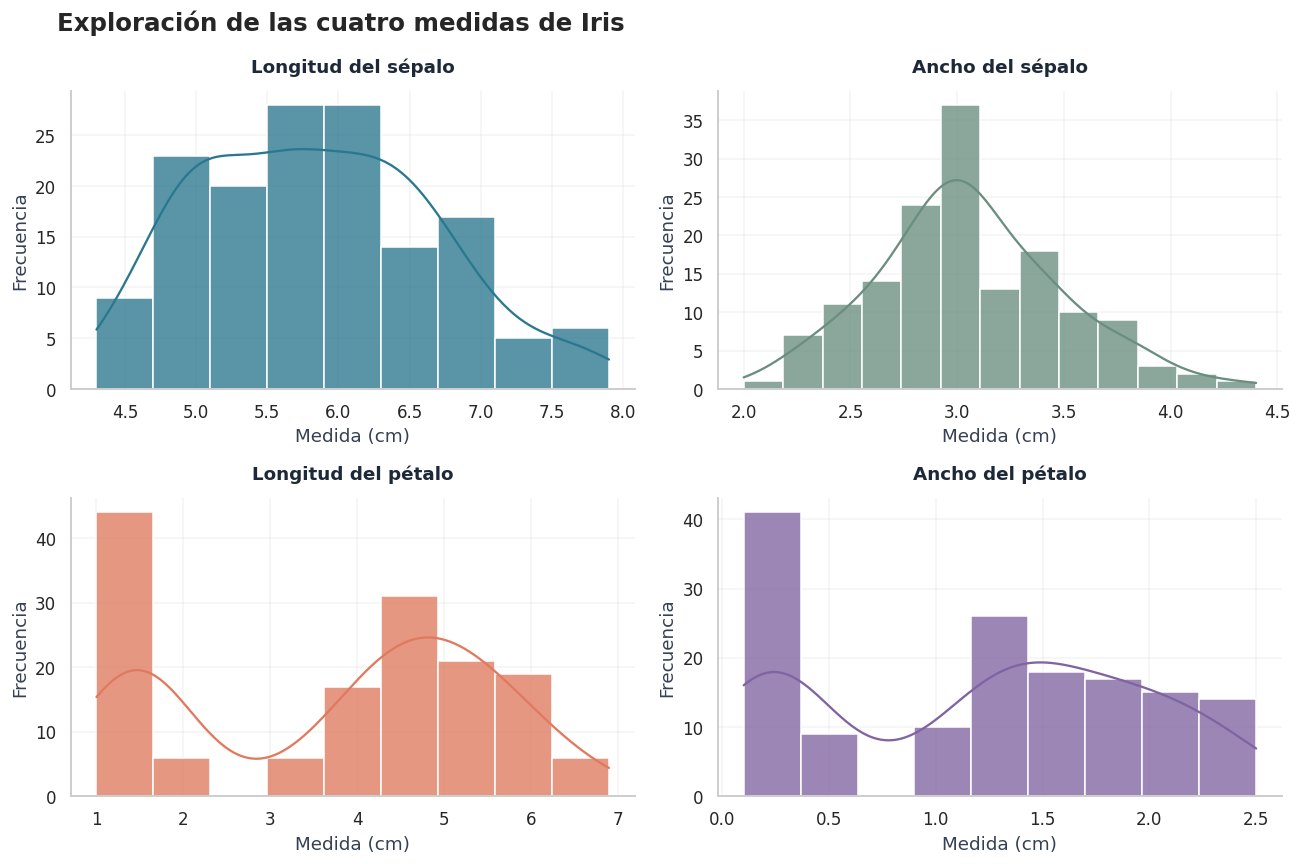

In [6]:
variables = [
    ("sepal_length", "Longitud del sépalo"),
    ("sepal_width", "Ancho del sépalo"),
    ("petal_length", "Longitud del pétalo"),
    ("petal_width", "Ancho del pétalo")
]
colores = ["#2A788E", "#6A8E7F", "#E07A5F", "#8064A2"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Exploración de las cuatro medidas de Iris",
             fontsize=16, fontweight="bold", x=0.05, ha="left")

for ax, (variable, titulo), color in zip(axes.flat, variables, colores):
    sns.histplot(data=iris, x=variable, kde=True, color=color,
                 alpha=0.78, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Medida (cm)")
    ax.set_ylabel("Frecuencia")

sns.despine()
plt.tight_layout()
plt.show()

### ¿Cómo elegir filas y columnas?

| Código | Organización | Uso recomendado |
|---|---|---|
| `plt.subplots(1, 2)` | 2 gráficos horizontales | Comparar dos variables |
| `plt.subplots(1, 3)` | 3 gráficos horizontales | Revisar tres variables rápidamente |
| `plt.subplots(2, 2)` | 4 gráficos en cuadrícula | Comparar cuatro variables |
| `plt.subplots(2, 2, sharex=True, sharey=True)` | 4 gráficos con ejes compartidos | Comparar gráficos que usan escalas comparables |

Compartir ejes (`sharex`, `sharey`) facilita la comparación solo cuando tiene sentido que los gráficos usen la misma escala. No conviene aplicarlo automáticamente a variables con unidades o rangos muy distintos.

## 3. Relación entre variables: dispersión, tendencia y lectura visual

Un diagrama de dispersión ayuda a observar si dos variables numéricas se mueven juntas. `sns.regplot()` agrega una línea de tendencia que resume la relación lineal observada.

Mejoraremos la presentación con transparencia en los puntos, una línea de tendencia visible y etiquetas descriptivas. La línea de tendencia no demuestra causalidad: resume un patrón observado.

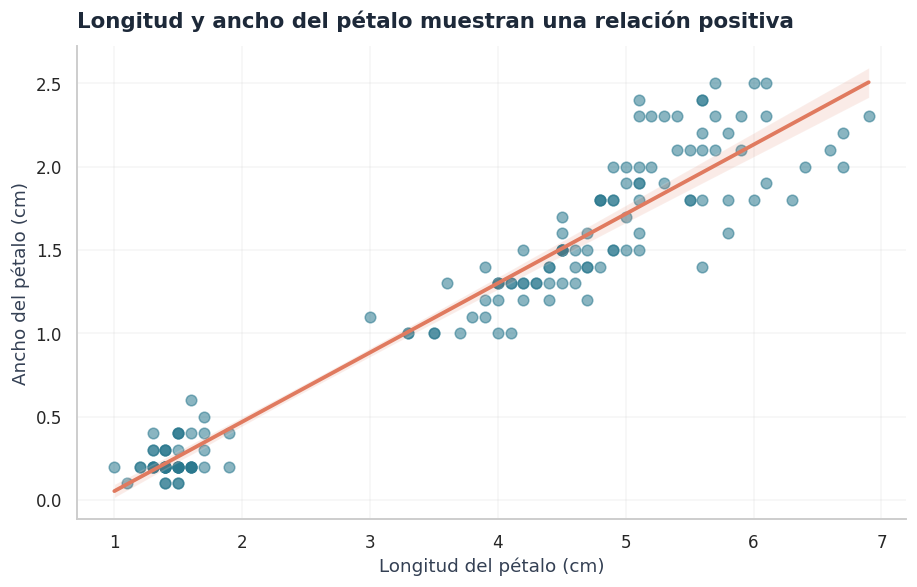

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.regplot( # sns.regplot(): dibuja los puntos y agrega una línea de tendencia lineal.
    data=iris,
    x="petal_length",
    y="petal_width",
    scatter_kws={"alpha": 0.55, "s": 48, "color": "#2A788E"}, # "alpha": 0.55: hace que los puntos sean semitransparentes y "s": 48: controla el tamaño de los puntos.
    line_kws={"color": "#E07A5F", "linewidth": 2.5}, # 	scatter_kws: permite personalizar los puntos del gráfico y line_kws: permite personalizar la línea de tendencia.
    ax=ax # ax=ax: dibuja todo dentro del espacio que creamos con plt.subplots().
)
ax.set_title("Longitud y ancho del pétalo muestran una relación positiva",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Longitud del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.grid(alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

### Comparar la relación por especie

El color permite ver si los grupos se comportan de manera diferente.

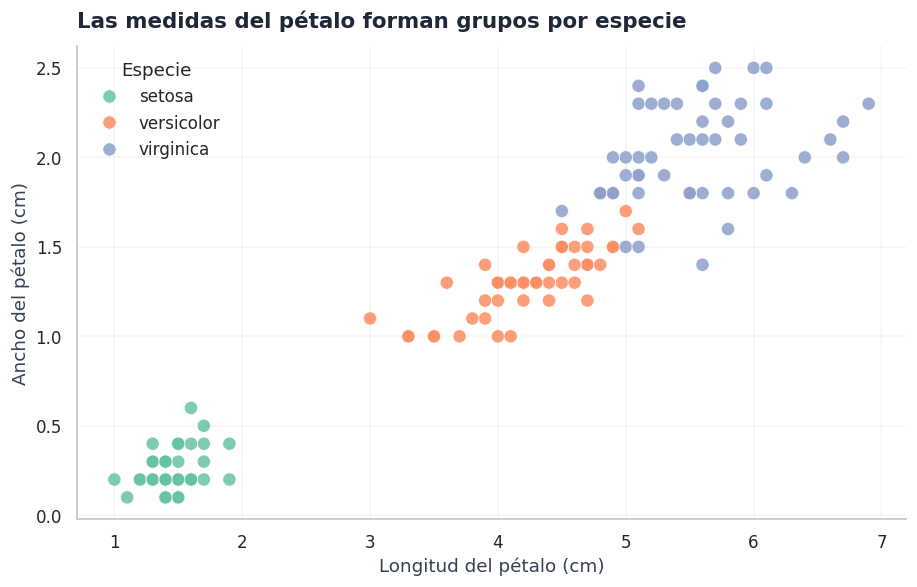

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.scatterplot(
    data=iris,
    x="petal_length",
    y="petal_width",
    hue="species", # hue="species": asigna un color a cada especie.
    palette="Set2",
    s=75,
    alpha=0.85,
    edgecolor="white", # edgecolor="white": agrega un borde blanco a los puntos para ayudar a distinguirlos.
    linewidth=0.5,
    ax=ax
)
ax.set_title("Las medidas del pétalo forman grupos por especie",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Longitud del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.legend(title="Especie", frameon=False, ncol=1)
ax.grid(alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

## 4. Mapa de calor de correlación con escala controlada

El mapa de calor permite revisar varias relaciones de un vistazo. Para hacerlo más legible, mostraremos solo la información útil, anotaremos los valores y fijaremos una escala común de -1 a 1.

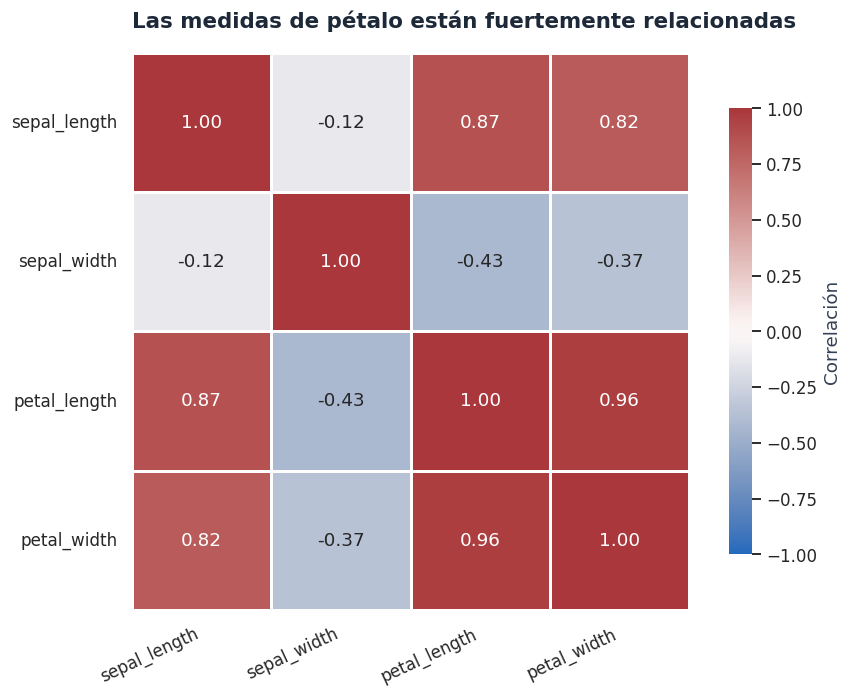

In [11]:
correlacion = iris.select_dtypes(include="number").corr() # select_dtypes(include="number") selecciona únicamente las columnas numéricas y .corr() calcula la matriz de correlación entre esas columnas.


plt.figure(figsize=(8.5, 6.5))
ax = sns.heatmap( # sns.heatmap(): convierte la matriz en una visualización de colores.
    correlacion,
    annot=True, # annot=True: escribe los valores numéricos dentro de cada celda.
    cmap="vlag", # cmap="vlag": selecciona una paleta divergente para distinguir correlaciones positivas y negativas.
    vmin=-1, # vmin=-1 y vmax=1: fijan los límites de la escala.
    vmax=1,
    center=0, # center=0: establece el centro de la escala en cero.
    fmt=".2f", # fmt=".2f": muestra los valores con dos decimales.
    linewidths=0.8, # linewidths=0.8: separa visualmente las celdas.
    linecolor="white",
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Correlación"}
)
ax.set_title("Las medidas de pétalo están fuertemente relacionadas",
             fontsize=14, fontweight="bold", loc="left", pad=16)
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**¿Por qué fijamos `vmin=-1` y `vmax=1`?** Para que los colores representen la misma escala de correlación. Si cada mapa ajusta sus propios límites, una relación débil podría parecer visualmente más intensa.

La diagonal siempre vale 1 porque cada variable está perfectamente correlacionada consigo misma. La matriz es simétrica: la correlación entre A y B es la misma que entre B y A.

### Reto final

Construye una figura con **cuatro gráficos en una cuadrícula de 2 × 2**, con una apariencia coherente y lista para presentar.

Requisitos:
- Usa `plt.subplots(2, 2, figsize=(...))`.
- Incluye al menos un histograma, un diagrama de caja y un gráfico de dispersión.
- Usa títulos que expliquen qué se está comparando.
- Aplica una paleta consistente y reduce el ruido visual.


Plantilla para completar: